# Proof validity · Model visualizations

Run cells in order from the Notebooks directory. Sections 1–3 read saved predictions, sections 4–7 describe the labeled corpus, and sections 8–13 compare models, refit the TF-IDF baseline at different training sizes and group test accuracy by proof symbol count. Each plot is exported as a vector PDF and a PNG in `Results/visualizations/`. Plots 1–3 and 13 use 1200 dpi.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm
from matplotlib.lines import Line2D
import numpy as np
import pandas as pd
from sklearn.metrics import confusion_matrix, f1_score

results = Path("../Results")
out = results / "visualizations"
out.mkdir(exist_ok=True)
scores = pd.read_csv(results / "proof_scores.csv")
models = ["TF-IDF", "DistilBERT", "ModernBERT-base", "MathBERT", "DeBERTa-v3-base"]
names = ["TF-IDF + LR", "DistilBERT", "ModernBERT", "MathBERT", "DeBERTa-v3"]
test = scores.query("dataset == 'test'").copy()
challenge = scores.query("dataset == 'challenge'").copy()

for subset, expected_size in ((test, 89), (challenge, 42)):
    assert subset.groupby("model").size().to_dict() == {model: expected_size for model in models}
assert scores["invalid_score"].between(0, 1).all()
away_from_tie = scores["invalid_score"] != 0.5
assert ((scores.loc[away_from_tie, "invalid_score"] > 0.5) == (scores.loc[away_from_tie, "predicted"] == "Invalid")).all()

ink, muted, grid = "#172F3B", "#4D606B", "#DAE3E6"
teal, rust, purple = "#087F80", "#AE4824", "#665999"
plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 12, "text.color": ink,
                     "axes.labelcolor": ink, "xtick.color": muted, "ytick.color": ink,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.spines.left": False, "axes.edgecolor": grid, "pdf.fonttype": 42})

def export(fig, name, dpi=300):
    for extension in ("pdf", "png"):
        fig.savefig(out / f"{name}.{extension}", dpi=dpi, facecolor="white", bbox_inches="tight", pad_inches=0.18)
    plt.show()
    plt.close(fig)

## 1. Where did each proof fall relative to the decision boundary?

Each point is one labeled test proof. Horizontal position is its model score for Invalid. Vertical jitter separates points and has no statistical meaning. TF-IDF uses the Invalid column of `predict_proba`; the BERTs use the Invalid column after softmax. These are uncalibrated scores. The native predictions determine all counts, including exact ties.

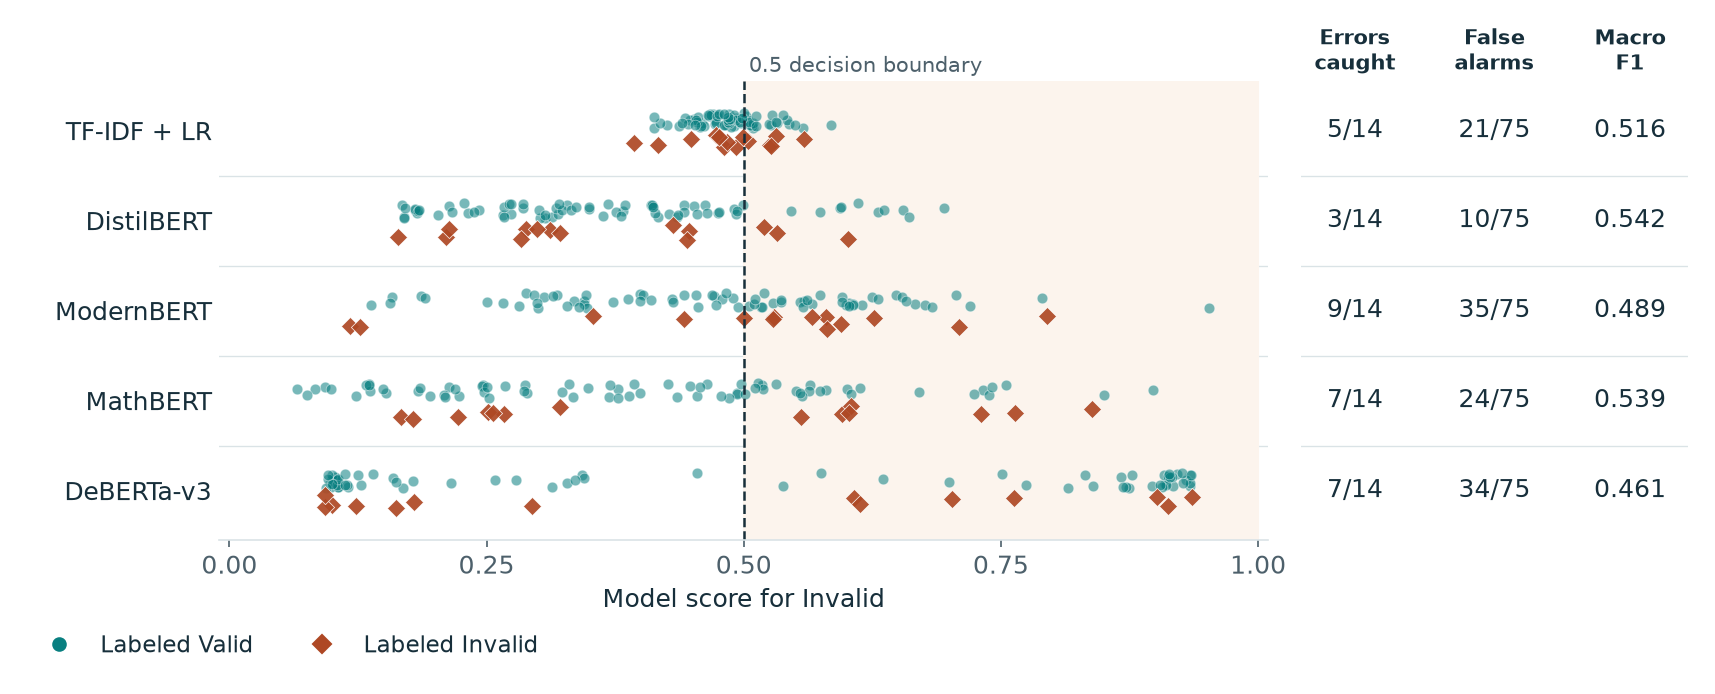

In [2]:
fig, (ax, table) = plt.subplots(1, 2, figsize=(11.8, 4.5), gridspec_kw={"width_ratios": [3.25, 1.2]})
fig.subplots_adjust(top=0.88, bottom=0.20, left=0.15, right=0.98, wspace=0.045)
ax.axvspan(0.5, 1, color="#FCF4ED")
ax.axvline(0.5, linestyle="--", color=ink, lw=1.2)
ax.text(0.505, 1.02, "0.5 decision boundary", transform=ax.get_xaxis_transform(), color=muted, fontsize=10)
rng = np.random.default_rng(42)
for i, model in enumerate(models):
    data = test[test.model == model].sort_values("clean_row_index")
    for label, offset, color, shape in [("Valid", -0.11, teal, "o"), ("Invalid", 0.13, rust, "D")]:
        part = data[data.actual == label]
        y = i + offset + rng.uniform(-0.085, 0.085, len(part))
        ax.scatter(part.invalid_score, y, s=26 if label == "Valid" else 38, c=color, marker=shape,
                   alpha=0.55 if label == "Valid" else 0.92, linewidths=0.35, edgecolors="white")
    tn, fp, fn, tp = confusion_matrix(data.actual, data.predicted, labels=["Valid", "Invalid"]).ravel()
    for x, value in zip([0.14, 0.50, 0.85], [f"{tp}/14", f"{fp}/75", f"{f1_score(data.actual, data.predicted, average='macro'):.3f}"]):
        table.text(x, i, value, ha="center", va="center", fontsize=12)
for panel in (ax, table):
    panel.set_ylim(4.55, -0.55)
    for y in np.arange(0.5, 4, 1):
        panel.axhline(y, color=grid, lw=0.65, zorder=0)
ax.set(xlim=(-0.01, 1.01), yticks=range(5), yticklabels=names, xlabel="Model score for Invalid")
ax.tick_params(axis="y", length=0)
ax.set_xticks([0, .25, .5, .75, 1])
table.set_xlim(0, 1)
table.set_axis_off()
for x, title in zip([0.14, 0.50, 0.85], ["Errors\ncaught", "False\nalarms", "Macro\nF1"]):
    table.text(x, 1.01, title, transform=table.transAxes, ha="center", va="bottom", fontsize=10, weight="bold")
handles = [Line2D([], [], color=c, marker=m, linestyle="none", label=s) for c, m, s in
           [(teal, "o", "Labeled Valid"), (rust, "D", "Labeled Invalid")]]
fig.legend(handles=handles, loc="lower left", bbox_to_anchor=(0.035, -0.005), ncol=2, frameon=False, fontsize=11)
export(fig, "01_test_score_strip_plot", dpi=1200)

## 2. What changed when review reasons were available during training?

The four BERTs always receive just the theorem and proof at test time. Lines connect the two fine-tuned versions of a model. The TF-IDF reason experiment used a reason at test time too, so this comparison uses the BERT experiments. The triangles show the separate zero-update baseline for Macro F1.

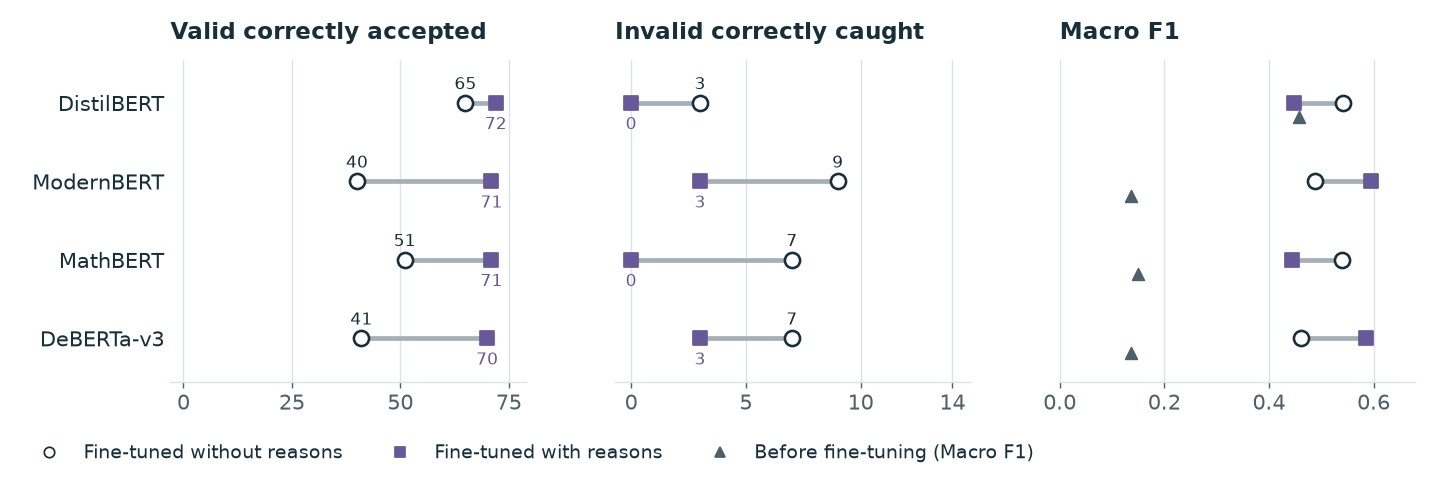

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.9), sharey=True)
fig.subplots_adjust(top=0.87, bottom=0.21, left=0.14, right=0.97, wspace=0.25)
for i, model in enumerate(models[1:]):
    saved = pd.read_csv(results / model / "predictions.csv").query("split == 'test'")
    endpoints = []
    for variant in ("without_review_reason", "with_training_review_reason"):
        data = saved[saved.training_input == variant]
        tn, fp, fn, tp = confusion_matrix(data.actual, data.predicted, labels=["Valid", "Invalid"]).ravel()
        endpoints.append((tn, tp, f1_score(data.actual, data.predicted, average="macro")))
    untrained = pd.read_csv(results / model / "without_training" / "metrics.csv").query("Split == 'test'").iloc[0]
    for j, ax in enumerate(axes):
        first, second = endpoints[0][j], endpoints[1][j]
        ax.plot([first, second], [i, i], color="#A4B0B5", lw=2.7, zorder=1)
        ax.scatter(first, i, color="white", edgecolor=ink, lw=1.5, s=76, zorder=3)
        ax.scatter(second, i, color=purple, marker="s", s=62, zorder=4)
        if j < 2:
            ax.annotate(str(first), (first, i), xytext=(0, 8), textcoords="offset points", ha="center", fontsize=10)
            ax.annotate(str(second), (second, i), xytext=(0, -15), textcoords="offset points", ha="center", fontsize=10, color=purple)
        else:
            ax.scatter(untrained["Macro F1"], i + .18, marker="^", s=45, color=muted, zorder=3)
for ax, title, limit, ticks in zip(axes, ["Valid correctly accepted", "Invalid correctly caught", "Macro F1"],
                                  [(-3, 79), (-0.7, 14.8), (0, .68)], [[0, 25, 50, 75], [0, 5, 10, 14], [0, .2, .4, .6]]):
    ax.set(xlim=limit, xticks=ticks, ylim=(3.55, -0.55), yticks=range(4), yticklabels=names[1:])
    ax.set_title(title, loc="left", fontsize=13, weight="bold", pad=12)
    ax.grid(axis="x", color=grid, lw=0.8)
    ax.set_axisbelow(True)
    ax.tick_params(axis="y", length=0)
fig.legend(handles=[Line2D([], [], marker=marker, markerfacecolor=color, markeredgecolor=edge, ls="none", label=label)
                    for marker, color, edge, label in [("o","white",ink,"Fine-tuned without reasons"),
                    ("s",purple,purple,"Fine-tuned with reasons"),("^",muted,muted,"Before fine-tuning (Macro F1)")]],
           loc="lower left", bbox_to_anchor=(.035, .008), ncol=3, frameon=False, fontsize=11)
export(fig, "02_review_reason_dumbbell_plot", dpi=1200)

## 3. Did a flawed edit move the score enough to change the label?

For each original and its primary edit, subtract the original Invalid score from the edited score. A positive change moves toward Invalid. A dot marks a proof that actually crossed to Invalid. Some theorems have two proof versions; the row index identifies the version. These 16 originals were selected because all five models accepted them.

Symbol edits flagged: 0 / 45 decisions


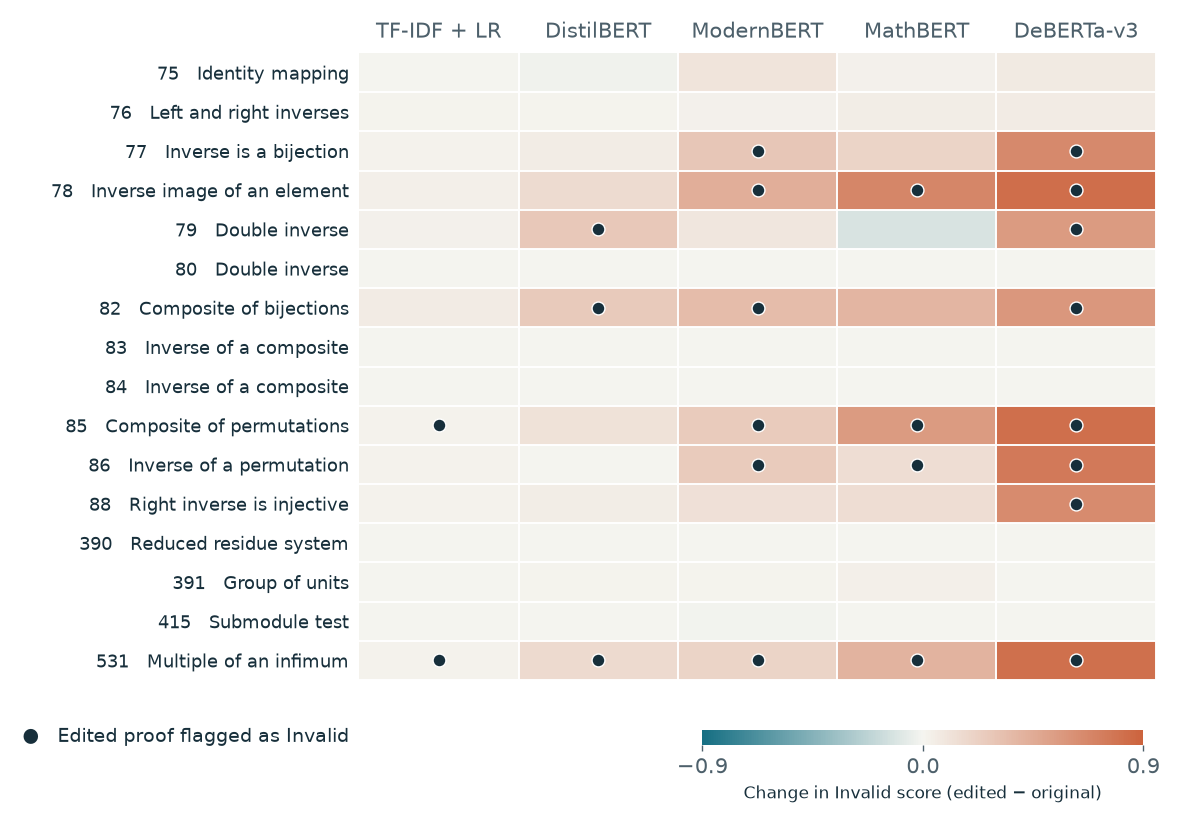

In [4]:
original = challenge[challenge.variant_id.str.endswith("-original")].pivot(index="clean_row_index", columns="model", values="invalid_score")
edited = challenge[challenge.variant_id.str.endswith("-primary")]
delta = (edited.pivot(index="clean_row_index", columns="model", values="invalid_score") - original)[models].sort_index()
caught = edited.pivot(index="clean_row_index", columns="model", values="predicted").loc[delta.index, models].eq("Invalid")
assert len(delta) == 16 and challenge[challenge.variant_id.str.endswith("-original")].predicted.eq("Valid").all()
titles = {75:"Identity mapping", 76:"Left and right inverses", 77:"Inverse is a bijection",
          78:"Inverse image of an element", 79:"Double inverse", 80:"Double inverse", 82:"Composite of bijections",
          83:"Inverse of a composite", 84:"Inverse of a composite", 85:"Composite of permutations",
          86:"Inverse of a permutation", 88:"Right inverse is injective", 390:"Reduced residue system",
          391:"Group of units", 415:"Submodule test", 531:"Multiple of an infimum"}
fig, ax = plt.subplots(figsize=(9.8, 6.6))
fig.subplots_adjust(top=.92, bottom=.16, left=.31, right=.96)
cmap = LinearSegmentedColormap.from_list("score_change", ["#166F83", "#F5F5F0", "#CC633D"])
bound = max(0.1, np.ceil(delta.abs().to_numpy().max()*10)/10)
im = ax.imshow(delta, cmap=cmap, norm=TwoSlopeNorm(0, -bound, bound), aspect="auto")
ys, xs = np.where(caught)
ax.scatter(xs, ys, color=ink, edgecolors="white", linewidths=.8, s=55)
ax.set_xticks(range(5), labels=names)
ax.xaxis.tick_top()
ax.set_yticks(range(len(delta)), labels=[f"{i}   {titles[i]}" for i in delta.index], fontsize=10.5)
ax.tick_params(axis="both", length=0, pad=6)
ax.set_xticks(np.arange(.5, 5), minor=True)
ax.set_yticks(np.arange(.5, len(delta)), minor=True)
ax.grid(which="minor", color="white", linewidth=1.1)
ax.tick_params(which="minor", length=0)
for spine in ax.spines.values():
    spine.set_visible(False)
fig.text(.035, .085, "●   Edited proof flagged as Invalid", fontsize=11)
cax = fig.add_axes([.59, .081, .36, .019])
bar = fig.colorbar(im, cax=cax, orientation="horizontal", ticks=[-bound, 0, bound])
bar.set_label("Change in Invalid score (edited − original)", fontsize=10)
bar.outline.set_visible(False)
symbols = ["84-primary","84-symbol-2","84-symbol-3","390-primary","390-symbol-2","390-symbol-3",
           "531-symbol-1","531-symbol-2","531-symbol-3"]
symbol_preds = challenge[challenge.variant_id.isin(symbols)]
assert len(symbol_preds) == 45
print(f"Symbol edits flagged: {symbol_preds.predicted.eq('Invalid').sum()} / {len(symbol_preds)} decisions")
export(fig, "03_proof_edit_score_change_heatmap", dpi=1200)

## 4. Label counts by split

Counts use the modeling copies after training augmentation. Rows without a validity label are excluded. Valid and Invalid refer to the submitted proof.

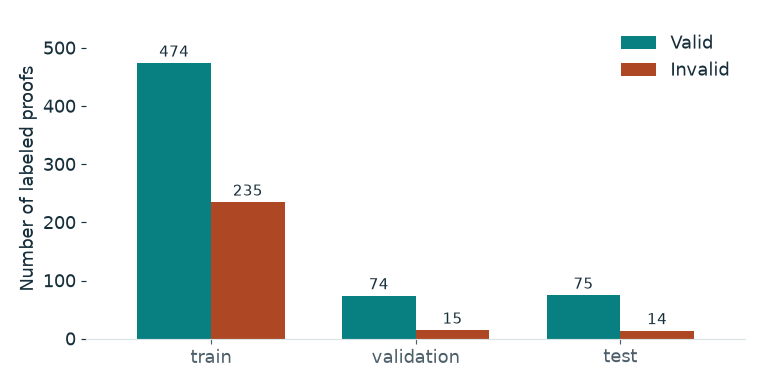

In [5]:
import json
import re
from collections import Counter
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS, TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, precision_recall_curve, roc_auc_score, roc_curve
from sklearn.pipeline import make_pipeline

split_names = ["train", "validation", "test"]
labels = ["Valid", "Invalid"]
label_colors = [teal, rust]
parts = []
for split in split_names:
    for file in sorted((Path("../Data/splits") / split).glob("proofwiki_review_*.json")):
        rows = json.loads(file.read_text(encoding="utf-8"))
        parts.append(pd.DataFrame(rows).assign(split=split, review_file=file.stem))
proofs = pd.concat(parts, ignore_index=True).dropna(subset=["validity"]).copy()
assert proofs.clean_row_index.is_unique and proofs.validity.isin(labels).all()
assert proofs.groupby("theorem_id").split.nunique().max() == 1
counts = pd.crosstab(proofs.split, proofs.validity).loc[split_names, labels]

fig, ax = plt.subplots(figsize=(7, 3.4), layout="constrained")
counts.plot.bar(ax=ax, color=label_colors, rot=0, width=.72)
for bars in ax.containers:
    ax.bar_label(bars, padding=2, fontsize=10)
ax.set(xlabel="", ylabel="Number of labeled proofs", ylim=(0, counts.max().max() * 1.16))
ax.legend(title=None, frameon=False)
export(fig, "04_label_counts_by_split")

## 5. Proof length by label

A token here is a word, number, LaTeX command or individual non-space symbol. Count only the proof text. Boxes show the middle 50%, lines show medians, and dots beyond the whiskers show outliers. The log axis keeps short and long proofs visible.

split       validity
test        Invalid     193.5
            Valid       122.0
train       Invalid     169.0
            Valid       156.0
validation  Invalid     250.0
            Valid       146.0


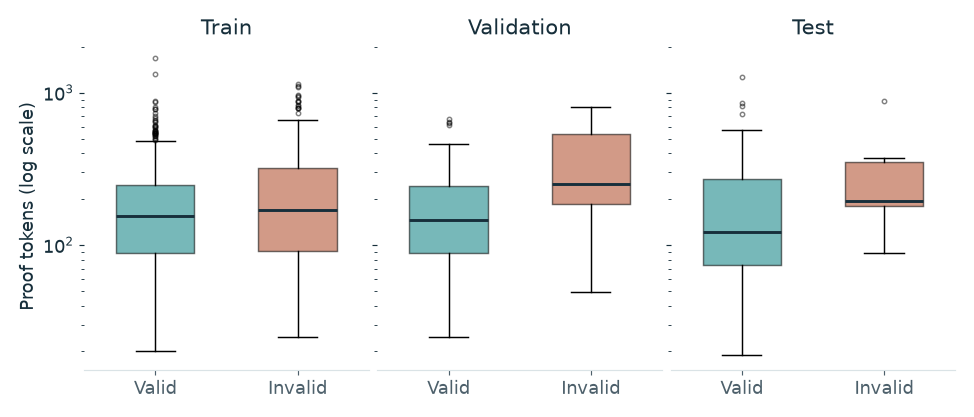

In [6]:
token_pattern = re.compile(r"\\[A-Za-z]+|[A-Za-z]+|\d+(?:\.\d+)?|[^\s]")
proofs["proof_tokens"] = proofs.proof_text.map(lambda text: len(token_pattern.findall(text)))
assert proofs.proof_tokens.min() > 0
fig, axes = plt.subplots(1, 3, figsize=(9, 3.7), sharey=True, layout="constrained")
for ax, split in zip(axes, split_names):
    groups = [proofs.loc[(proofs.split == split) & (proofs.validity == label), "proof_tokens"] for label in labels]
    boxes = ax.boxplot(groups, patch_artist=True, tick_labels=labels, widths=.55,
                       medianprops={"color": ink, "linewidth": 2},
                       flierprops={"markersize": 3, "alpha": .5})
    for patch, color in zip(boxes["boxes"], label_colors):
        patch.set_facecolor(color)
        patch.set_alpha(.55)
    ax.set(title=split.capitalize(), yscale="log")
axes[0].set_ylabel("Proof tokens (log scale)")
print(proofs.groupby(["split", "validity"]).proof_tokens.median().rename("Median tokens").to_string())
export(fig, "05_proof_length_by_label")

## 6. Counts by proof origin

All records come from the ProofWiki corpus. Origin distinguishes the original proof text from a synthetic replacement. The training distribution includes both; validation and test contain original proofs. The files do not provide subject or difficulty labels.

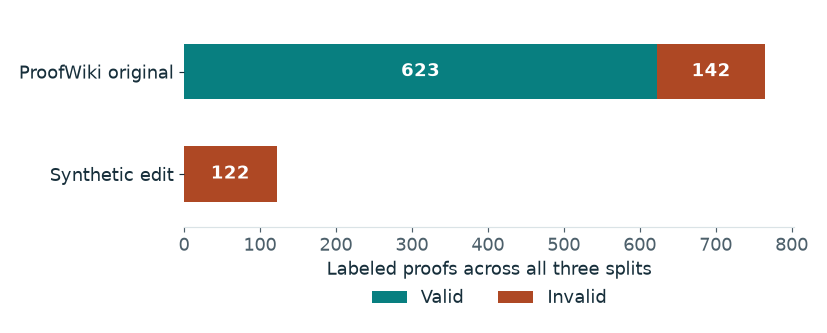

In [7]:
proofs["origin"] = np.where(proofs["is_synthetic"].eq(True), "Synthetic edit", "ProofWiki original")
source_counts = pd.crosstab(proofs.origin, proofs.validity).reindex(
    index=["ProofWiki original", "Synthetic edit"], columns=labels, fill_value=0)
fig, ax = plt.subplots(figsize=(7.6, 2.9), layout="constrained")
source_counts.plot.barh(stacked=True, ax=ax, color=label_colors, width=.54)
for bars in ax.containers:
    ax.bar_label(bars, labels=[str(int(v)) if v else "" for v in bars.datavalues],
                 label_type="center", color="white", weight="bold")
ax.set(xlabel="Labeled proofs across all three splits", ylabel="")
ax.invert_yaxis()
ax.legend(title=None, loc="upper center", bbox_to_anchor=(.5, -.22), ncol=2, frameon=False)
export(fig, "06_proof_origin_counts")

## 7. Frequent words in training proofs

For each label, take the eight content words appearing in the most proofs. Compare the percentage of proofs containing each word, counting a word at most once per proof. This describes training text, including synthetic edits. It does not measure the weights of the character n-gram classifier.

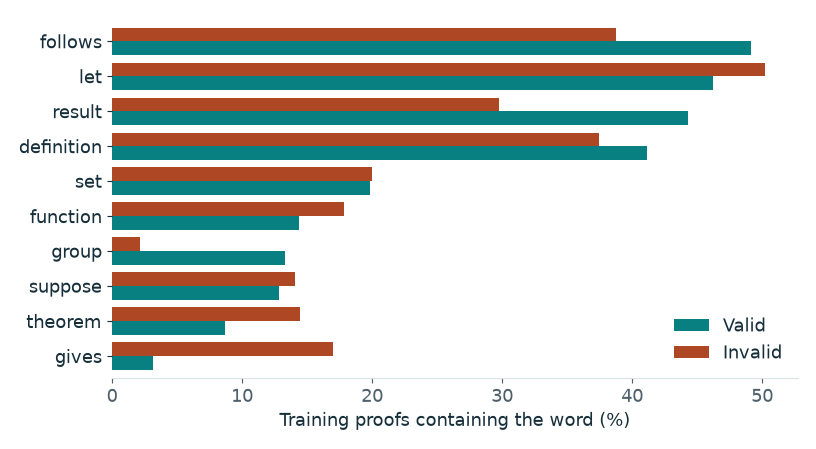

In [8]:
train = proofs.loc[proofs.split == "train"].copy()
validation = proofs.loc[proofs.split == "validation"].copy()
frequencies = {}
for label in labels:
    subset = train.loc[train.validity == label, "proof_text"]
    word_counts = Counter()
    for text in subset:
        prose = re.sub(r"\$\$.*?\$\$|\$[^$]*\$", " ", text, flags=re.S)
        words = set(re.findall(r"[a-z]{3,}", prose.lower())) - ENGLISH_STOP_WORDS
        word_counts.update(words)
    frequencies[label] = pd.Series(word_counts, dtype=float) * 100 / len(subset)
frequency = pd.DataFrame(frequencies).fillna(0).sort_index()
top_words = frequency["Valid"].nlargest(8).index.union(frequency["Invalid"].nlargest(8).index)
top = frequency.loc[top_words].sort_values("Valid")
fig, ax = plt.subplots(figsize=(7.5, max(4, .40 * len(top))), layout="constrained")
top.plot.barh(ax=ax, color=label_colors, width=.78)
ax.set(xlabel="Training proofs containing the word (%)", ylabel="")
ax.legend(frameon=False)
export(fig, "07_frequent_words_by_label")

## 8. Test confusion matrices

The existing model folders contain their individual matrices. This panel places all five theorem-and-proof models on one scale, using the same 89 test proofs and the models' saved decisions.

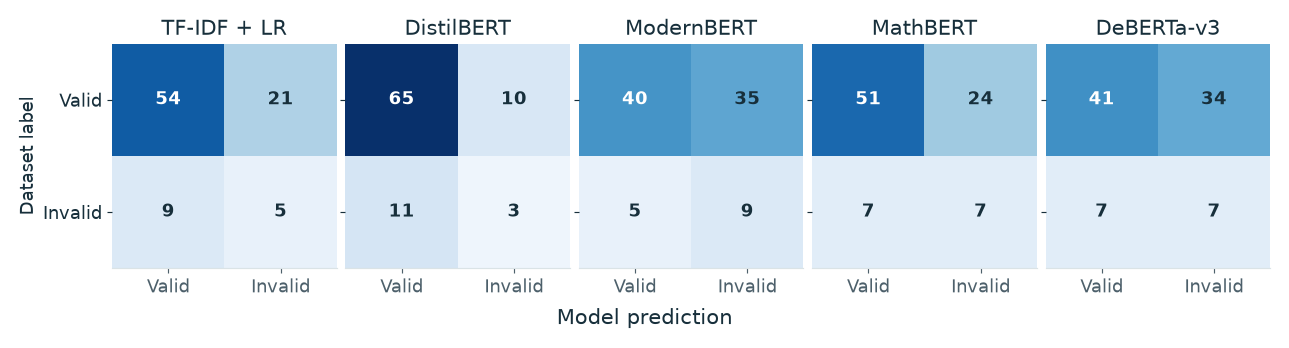

In [9]:
test_rows = proofs.loc[proofs.split == "test"].set_index("clean_row_index").sort_index()
test_views = {}
matrices = []
for model in models:
    data = test.loc[test.model == model].set_index("clean_row_index").sort_index()
    assert data.index.equals(test_rows.index) and data.actual.equals(test_rows.validity)
    assert data.theorem_id.equals(test_rows.theorem_id)
    test_views[model] = data
    matrices.append(confusion_matrix(data.actual, data.predicted, labels=labels))

fig, axes = plt.subplots(1, 5, figsize=(12, 3.1), layout="constrained")
vmax = max(matrix.max() for matrix in matrices)
for i, (ax, matrix, name) in enumerate(zip(axes, matrices, names)):
    ax.imshow(matrix, cmap="Blues", vmin=0, vmax=vmax)
    for (row, col), count in np.ndenumerate(matrix):
        ax.text(col, row, str(count), ha="center", va="center", weight="bold",
                color="white" if count > .55 * vmax else ink)
    ax.set(xticks=[0, 1], xticklabels=labels, yticks=[0, 1], title=name)
    ax.set_yticklabels(labels if i == 0 else ["", ""])
axes[0].set_ylabel("Dataset label")
fig.supxlabel("Model prediction")
export(fig, "08_test_confusion_matrices")

## 9. ROC and precision-recall curves

Invalid is the positive class. Curves sweep the saved continuous score. ROC AUC is the area under the ROC curve; AP is average precision. The dashed PR reference is the observed Invalid fraction.

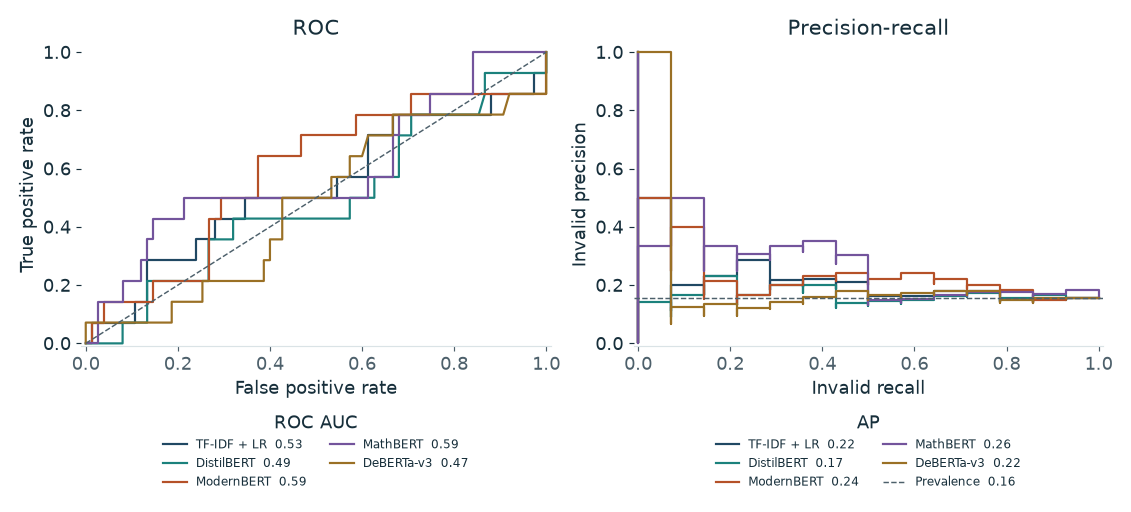

In [10]:
palette = ["#204863", "#1B817C", "#B55128", "#73549C", "#9A7025"]
fig, (roc_ax, pr_ax) = plt.subplots(1, 2, figsize=(10.5, 4.6), layout="constrained")
positive = test_rows.validity.eq("Invalid")
for model, name, color in zip(models, names, palette):
    score = test_views[model].invalid_score
    fpr, tpr, _ = roc_curve(positive, score)
    precision, recall, _ = precision_recall_curve(positive, score)
    roc_ax.plot(fpr, tpr, color=color, label=f"{name}  {roc_auc_score(positive, score):.2f}")
    pr_ax.step(recall, precision, where="post", color=color,
               label=f"{name}  {average_precision_score(positive, score):.2f}")
roc_ax.plot([0, 1], [0, 1], "--", color=muted, lw=1)
pr_ax.axhline(positive.mean(), ls="--", color=muted, lw=1, label=f"Prevalence  {positive.mean():.2f}")
roc_ax.set(xlabel="False positive rate", ylabel="True positive rate", title="ROC")
pr_ax.set(xlabel="Invalid recall", ylabel="Invalid precision", title="Precision-recall")
for ax, metric in ((roc_ax, "ROC AUC"), (pr_ax, "AP")):
    ax.set(xlim=(-.01, 1.01), ylim=(-.01, 1.03))
    ax.legend(title=metric, frameon=False, fontsize=8, loc="upper center", bbox_to_anchor=(.5, -.19), ncol=2)
export(fig, "09_test_roc_and_precision_recall")

## 10. Accuracy, Macro F1, Invalid precision and recall

Bars use saved test predictions. Whiskers are 95% percentile intervals from 2,000 paired bootstrap samples of test theorem IDs. Each draw includes all proof versions of the sampled theorem. The intervals describe test-sample uncertainty for the fitted models, not variability across independent training runs.

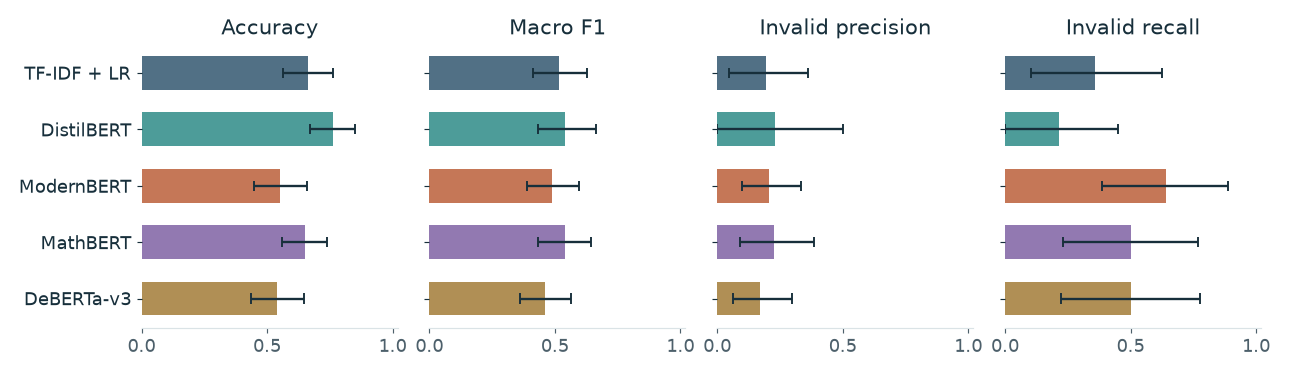

In [11]:
def four_metrics(counts):
    tn, fp, fn, tp = np.moveaxis(counts, -1, 0)
    def ratio(a, b):
        return np.divide(a, b, out=np.zeros_like(a, dtype=float), where=b != 0)
    return np.stack([ratio(tp + tn, tn + fp + fn + tp),
                     (ratio(2 * tp, 2 * tp + fp + fn) + ratio(2 * tn, 2 * tn + fp + fn)) / 2,
                     ratio(tp, tp + fp), ratio(tp, tp + fn)], axis=-1)

theorem_codes, theorem_ids = pd.factorize(test_rows.theorem_id)
rng = np.random.default_rng(42)
weights = rng.multinomial(len(theorem_ids), np.full(len(theorem_ids), 1 / len(theorem_ids)), size=2000)
fig, axes = plt.subplots(1, 4, figsize=(12, 3.3), sharey=True, layout="constrained")
metric_names = ["Accuracy", "Macro F1", "Invalid precision", "Invalid recall"]
for i, (model, matrix) in enumerate(zip(models, matrices)):
    data = test_views[model]
    pair_codes = 2 * positive.to_numpy(dtype=int) + data.predicted.eq("Invalid").to_numpy(dtype=int)
    by_theorem = np.zeros((len(theorem_ids), 4), dtype=int)
    np.add.at(by_theorem, (theorem_codes, pair_codes), 1)
    assert np.array_equal(by_theorem.sum(axis=0), matrix.ravel())
    values = four_metrics(matrix.ravel())
    lo, hi = np.quantile(four_metrics(weights @ by_theorem), [.025, .975], axis=0)
    for j, ax in enumerate(axes):
        ax.barh(i, values[j], height=.60, color=palette[i], alpha=.78)
        ax.hlines(i, lo[j], hi[j], color=ink, lw=1.6)
        ax.vlines([lo[j], hi[j]], i-.09, i+.09, color=ink, lw=1.3)
for ax, title in zip(axes, metric_names):
    ax.set(xlim=(0, 1.02), xticks=[0, .5, 1], title=title)
axes[0].set(yticks=range(len(names)), yticklabels=names)
axes[0].invert_yaxis()
export(fig, "10_test_metric_comparison")

## 11. TF-IDF learning curve

Refit the selected baseline at five training sizes. Each of five seeded orders adds whole review files, keeping versions of each theorem together. Scores use the same validation set, with no review reasons. The band spans the five validation scores across subset orders; at full size all orders use the same 709 proofs.

       proofs  training  validation    low   high
files                                            
3        88.8     0.930       0.438  0.310  0.499
6       176.8     0.891       0.469  0.387  0.535
12      354.4     0.840       0.477  0.399  0.535
18      530.8     0.835       0.486  0.443  0.509
24      709.0     0.802       0.501  0.501  0.501


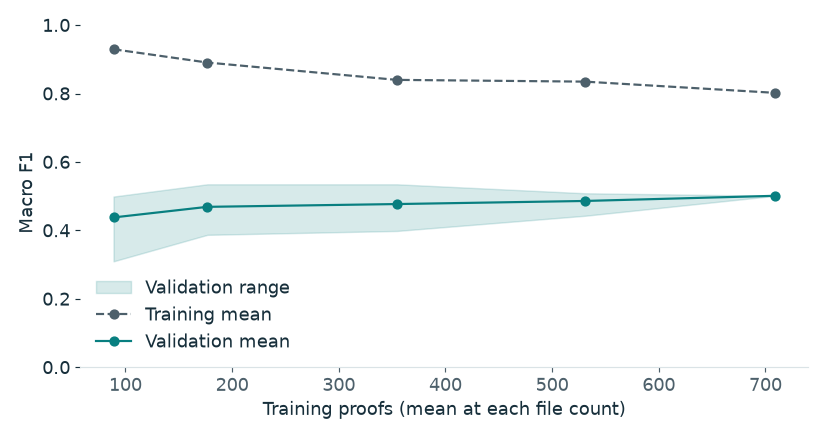

In [12]:
settings = json.loads((results / "TF-IDF" / "experiment.json").read_text(encoding="utf-8"))
params = settings["runs"]["without_review_reason"]
assert train.groupby("theorem_id").review_file.nunique().max() == 1
# Split membership is fixed; verify that train and validation share no proof, theorem or row.
for column in ["theorem_id", "theorem_text", "proof_text", "clean_row_index"]:
    assert set(train[column]).isdisjoint(validation[column])
def proof_input(rows):
    return rows.theorem_text + "\n" + rows.proof_text

files = sorted(train.review_file.unique())
sizes = [3, 6, 12, 18, len(files)]
sizes = sorted(set(size for size in sizes if size <= len(files)))
validation_text = proof_input(validation)
records = []
for seed in range(42, 47):
    order = np.random.default_rng(seed).permutation(files)
    for nfiles in sizes:
        if nfiles == len(files) and seed != 42:
            continue
        subset = train[train.review_file.isin(order[:nfiles])]
        assert subset.validity.nunique() == 2
        clf = make_pipeline(
            TfidfVectorizer(analyzer=params["analyzer"], ngram_range=tuple(params["ngram_range"]),
                            lowercase=params["lowercase"], min_df=params["min_df"]),
            LogisticRegression(C=params["C"], max_iter=params["max_iter"], class_weight=params["class_weight"]))
        text = proof_input(subset)
        clf.fit(text, subset.validity)
        train_f1 = f1_score(subset.validity, clf.predict(text), labels=labels, average="macro")
        val_f1 = f1_score(validation.validity, clf.predict(validation_text), labels=labels, average="macro")
        records.append((seed, nfiles, len(subset), train_f1, val_f1))
curve = pd.DataFrame(records, columns=["seed", "files", "proofs", "training", "validation"])
full = curve[curve.files == len(files)].iloc[0]
assert np.isclose(full.validation, params["validation_macro_f1"]) and full.proofs == len(train)
summary = curve.groupby("files").agg(proofs=("proofs", "mean"), training=("training", "mean"),
    validation=("validation", "mean"), low=("validation", "min"), high=("validation", "max"))
fig, ax = plt.subplots(figsize=(7.6, 3.9), layout="constrained")
ax.fill_between(summary.proofs, summary.low, summary.high, color=teal, alpha=.16, label="Validation range")
ax.plot(summary.proofs, summary.training, "o--", color=muted, label="Training mean")
ax.plot(summary.proofs, summary.validation, "o-", color=teal, label="Validation mean")
ax.set(xlabel="Training proofs (mean at each file count)", ylabel="Macro F1", ylim=(0, 1.02))
ax.legend(frameon=False)
print(summary.round(3).to_string())
export(fig, "11_tfidf_learning_curve")

## 12. Test score histograms by dataset label

Each panel uses the same score bins. Percentages are normalized separately within the 75 Valid and 14 Invalid test proofs. The dashed line marks 0.5. These scores express model preference and have not been calibrated as probabilities of mathematical error.

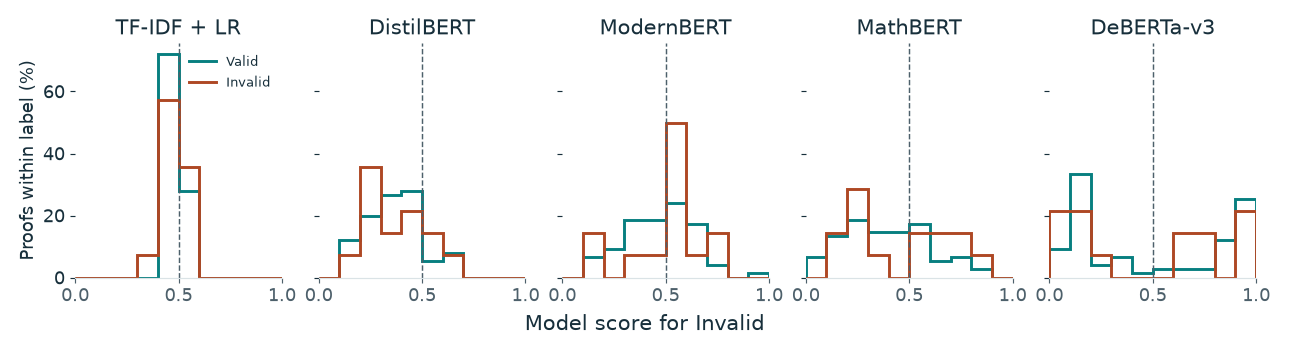

In [13]:
fig, axes = plt.subplots(1, 5, figsize=(12, 3.1), sharex=True, sharey=True, layout="constrained")
bins = np.linspace(0, 1, 11)
for ax, model, name in zip(axes, models, names):
    data = test_views[model]
    for label, color in zip(labels, label_colors):
        x = data.loc[data.actual == label, "invalid_score"]
        heights, _ = np.histogram(x, bins=bins)
        assert heights.sum() == len(x)
        ax.stairs(100 * heights / len(x), bins, color=color, linewidth=2, label=label)
    ax.axvline(.5, color=muted, lw=1, ls="--")
    ax.set(title=name, xlim=(0, 1), xticks=[0, .5, 1])
axes[0].set_ylabel("Proofs within label (%)")
axes[0].legend(frameon=False, fontsize=9)
fig.supxlabel("Model score for Invalid")
export(fig, "12_test_score_histograms")

## 13. Test accuracy by proof symbol count

Count repeated occurrences of mathematical notation in the full proof text between dollar delimiters. Each variable letter, numeric literal, operator or mathematical LaTeX command counts once. Spacing, font commands, TeX grouping braces and script markers are ignored. This is a token count, not a count of distinct glyphs. Three quantile groups are formed before examining predictions; ties stay together. Each cell shows the percentage and fraction of correctly classified proofs for one model trained without review reasons. Group sizes and class composition appear under the heatmap. Symbol count can vary with proof length and the mix of Valid and Invalid proofs.

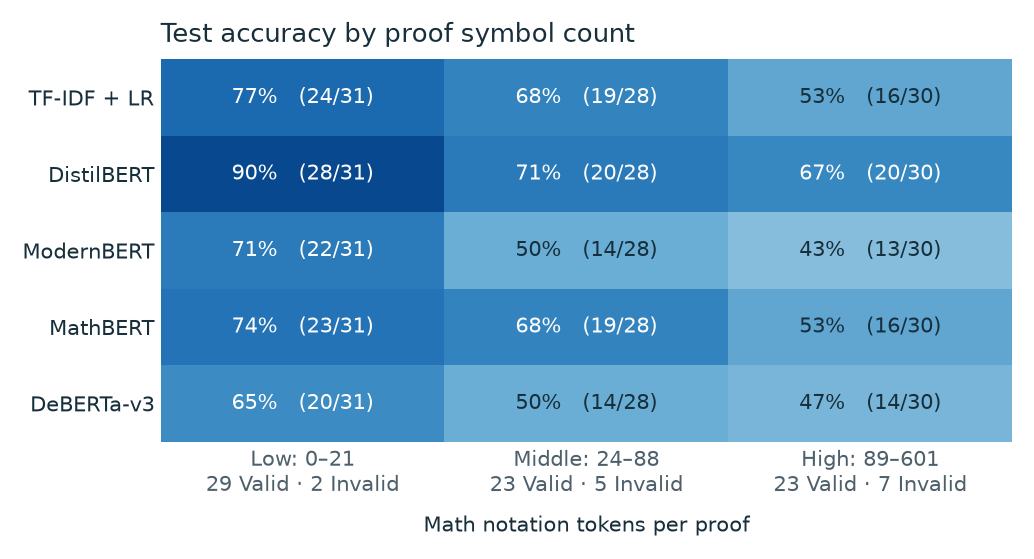

In [14]:
# Use the saved test predictions and the dataset loaded in section 4.
import re

math_span = re.compile(r"\$\$(.*?)\$\$|\$([^$]+)\$", re.S)
layout = re.compile(r"\\(?:begin|end|text)\s*\{[^{}]*\}")
notation = re.compile(r"\\[A-Za-z]+|\\[{}|]|[^\W\d_]|[0-9]+(?:\.[0-9]+)?|[+=*/<>!|()'\[\]\-−≤≥≠∈∉⊂⊆∪∩×÷∞∑∏√→↔]")
formatting = set("displaystyle textstyle scriptstyle mathop mathbin mathcal mathbb Bbb mathrm mathbf "
                 "left right quad qquad underbrace".split())

def count_symbols(proof):
    total = 0
    for match in math_span.finditer(proof):
        formula = layout.sub(" ", match.group(1) or match.group(2) or "")
        total += sum(token.lstrip("\\") not in formatting for token in notation.findall(formula))
    return total

assert count_symbols(r"Let $x_i \le 12$ and $$\displaystyle y=0$$.") == 7
assert count_symbols(r"No formula here.") == 0
rows = proofs.loc[proofs.split == "test", ["clean_row_index", "validity", "proof_text"]].copy()
rows["symbol_count"] = rows.proof_text.map(count_symbols)
rows["group"] = pd.qcut(rows.symbol_count, 3, labels=["Low", "Middle", "High"])
joined = test.merge(rows.drop(columns="proof_text"), on="clean_row_index", validate="many_to_one")
assert len(joined) == len(rows) * len(models) and joined.actual.eq(joined.validity).all()
joined["correct"] = joined.actual.eq(joined.predicted)
groups = rows.groupby("group", observed=True).agg(
    minimum=("symbol_count", "min"), maximum=("symbol_count", "max"), proofs=("validity", "size"),
    invalid=("validity", lambda x: x.eq("Invalid").sum()))
groups["valid"] = groups.proofs - groups.invalid
hits = joined.pivot_table(index="model", columns="group", values="correct", aggfunc="sum", observed=True)
hits = hits.loc[models, groups.index]
accuracy_pct = 100 * hits.div(groups.proofs, axis="columns")
assert hits.sum(axis=1).eq(joined.groupby("model").correct.sum().reindex(models)).all()

fig, ax = plt.subplots(figsize=(8, 4.2), layout="constrained")
ax.imshow(accuracy_pct, cmap="Blues", vmin=0, vmax=100, aspect="auto")
for i, model in enumerate(models):
    for j, group in enumerate(groups.index):
        pct = accuracy_pct.at[model, group]
        ax.text(j, i, f"{pct:.0f}%   ({hits.at[model, group]}/{groups.at[group, 'proofs']})",
                ha="center", va="center", color="white" if pct >= 60 else ink, fontsize=12)
ax.set_xticks(range(3), labels=[f"{g}: {r.minimum}–{r.maximum}\n{r.valid} Valid · {r.invalid} Invalid"
                               for g, r in groups.iterrows()])
ax.set_yticks(range(len(models)), labels=names)
ax.set_xlabel("Math notation tokens per proof", labelpad=10)
ax.set_title("Test accuracy by proof symbol count", loc="left", fontsize=15, pad=10)
ax.tick_params(length=0)
for spine in ax.spines.values():
    spine.set_visible(False)
export(fig, "13_accuracy_by_proof_symbol_count", dpi=1200)